# Data analysis
## Bissal Youssef - Lombardozzi Christian
### IUM project 2024/25

In [42]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import geopandas as gpd

df_releases = pd.read_csv('../data/releases.csv')
df_genres = pd.read_csv('../data/genres.csv')
df_movies = pd.read_csv('../data/movies.csv')
df_studios = pd.read_csv('../data/studios.csv')
df_themes = pd.read_csv('../data/themes.csv')
df_countries = gpd.read_file('../data/countries.csv')
df_languages = pd.read_csv('../data/languages.csv')
df_posters = pd.read_csv('../data/posters.csv')
df_reviews = pd.read_csv('../data/rotten_tomatoes_reviews.csv')
df_crew = pd.read_csv('../data/crew.csv')
df_posters = pd.read_csv('../data/posters.csv')
df_oscars = pd.read_csv('../data/the_oscar_awards.csv')
df_releases = pd.read_csv('../data/releases.csv')
df_actors = pd.read_csv('../data/actors.csv')


* Is there any currelation between the rating of a movie and the number of oscars won by its actors after the release?

In [64]:
#da completare



# Filtra gli attori vincitori di Oscar nelle categorie "Actor" e "Actress"
df_actors_oscar = df_oscars[(df_oscars['winner'] == True) &
                            (df_oscars['category'].isin(["Actor", "Actress"]))]

# Unisci con gli attori usando il nome
df_actors_oscar = df_actors_oscar.merge(df_actors, on='name', how='inner')

# Unisci con i dati dei film usando `film` e `name`
df_actors_oscar = df_actors_oscar.merge(df_movies, left_on='film', right_on='name',
                                        how='inner')


# Filtra gli attori che hanno vinto un Oscar dopo l'uscita del film
df_actors_oscar = df_actors_oscar[df_actors_oscar['year_ceremony'] > df_actors_oscar['year_film']]

# Conta il numero di attori vincitori di Oscar per ogni film
oscar_counts = df_actors_oscar.groupby('id_movie').size().reset_index(name='oscar_winners_count')

# Unisci i dati dei film con il conteggio degli attori vincitori di Oscar
df_movies = df_movies.merge(oscar_counts, left_on='id', right_on='id_movie', how='left')

# Sostituisci i NaN con 0
df_movies['oscar_winners_count'] = df_movies['oscar_winners_count'].fillna(0).astype(int)


KeyError: 'oscar_winners_count'

* Are the countries which produce more film translate a lot of films as well?

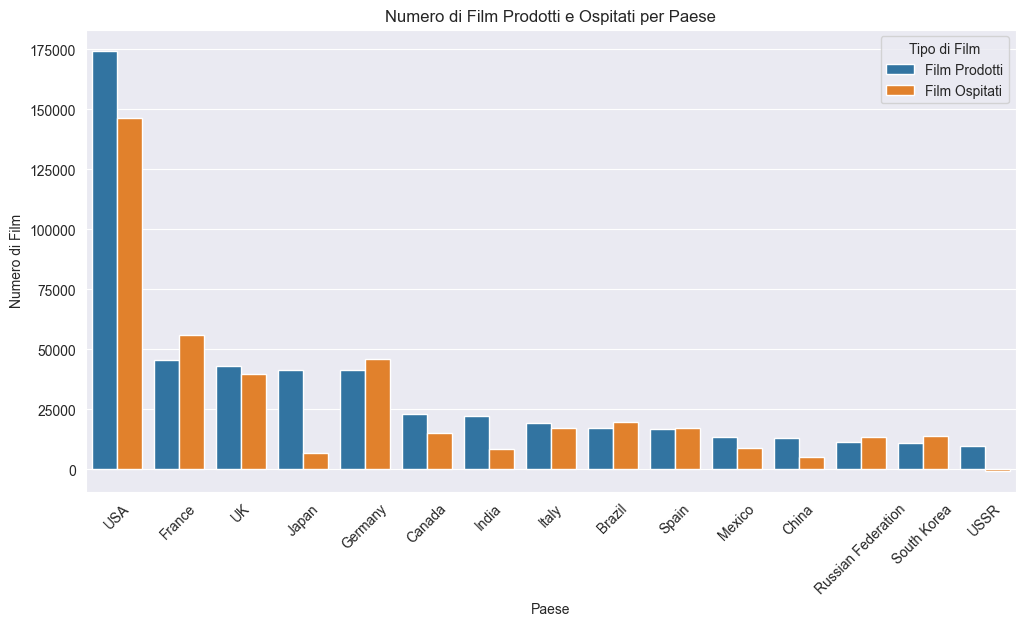

In [63]:

produced_films_per_country = df_countries['country'].value_counts().reset_index(name='produced_films')
produced_films_per_country.columns = ['country', 'produced_films']


hosted_films_per_country = df_releases['country'].value_counts().reset_index(name='hosted_films')
hosted_films_per_country.columns = ['country', 'hosted_films']

combined = pd.merge(produced_films_per_country, hosted_films_per_country, on='country', how='outer').fillna(0)

# Calcola i film ospitati esclusivamente (ossia film ospitati meno quelli prodotti)
combined['hosted_exclusively'] = combined['hosted_films'] - combined['produced_films']


top_countries = combined.nlargest(15, 'produced_films')


combined_melted = top_countries.melt(id_vars='country', value_vars=['produced_films', 'hosted_exclusively'],
                                     var_name='film_type', value_name='count')


combined_melted['film_type'] = combined_melted['film_type'].map({
    'produced_films': 'Film Prodotti',
    'hosted_exclusively': 'Film Ospitati'
})


plt.figure(figsize=(12, 6))
sns.barplot(data=combined_melted, x='country', y='count', hue='film_type')
plt.xlabel('Paese')
plt.ylabel('Numero di Film')
plt.title('Numero di Film Prodotti e Ospitati per Paese')
plt.xticks(rotation=45)
plt.legend(title='Tipo di Film')
plt.show()
